## Teste do fit na sensibilidade do chute inicial 

In [1]:
# INICIALIZAÇÃO DAS BIBLIOTECAS
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
%matplotlib inline

In [2]:
# FUNÇÃO PARA O CÁLCULO DA FRAÇÃO DE GORDURA
def dixon(s23,s46):
    rw = (s46 + s23)/2
    rf = (s46 - s23)/2         
    ff = rf / (rf + rw)    
    return(ff)

In [3]:
magField = 3.0      # tesla
hydroGyro = 42.57e6 # Hz/T
T2star = [0.030, 0.040, 0.051, 0.052, 0.062, 0.083, 0.023]
Fppmn = [5.3, 4.2, 2.75, 2.1, 1.3, 0.9, 4.7]
cn = [0.047, 0.039, 0.006, 0.12, 0.7, 0.088]

# FUNÇÃO DO FIT
def fat_water(x, ff):
    return np.absolute(ff*rho[0]*np.exp(-x/T2star[0])*np.exp((2.*np.pi*1j*Fppmn[0]*magField*hydroGyro/1e6)*x) + 
                       ff*rho[1]*np.exp(-x/T2star[1])*np.exp((2.*np.pi*1j*Fppmn[1]*magField*hydroGyro/1e6)*x) + 
                       ff*rho[2]*np.exp(-x/T2star[2])*np.exp((2.*np.pi*1j*Fppmn[2]*magField*hydroGyro/1e6)*x) + 
                       ff*rho[3]*np.exp(-x/T2star[3])*np.exp((2.*np.pi*1j*Fppmn[3]*magField*hydroGyro/1e6)*x) + 
                       ff*rho[4]*np.exp(-x/T2star[4])*np.exp((2.*np.pi*1j*Fppmn[4]*magField*hydroGyro/1e6)*x) +
                       ff*rho[5]*np.exp(-x/T2star[5])*np.exp((2.*np.pi*1j*Fppmn[5]*magField*hydroGyro/1e6)*x) +
                       (1-ff)*np.exp(-x/T2star[6])*np.exp((2.*np.pi*1j*Fppmn[6]*magField*hydroGyro/1e6)*x))

## 2% de gordura

In [4]:
# GERANDO OS DADOS PARA 2% DE GORDURA

fatPercent = 0.02

t = [0.0011515, 0.0011515*2, 0.0011515*3, 0.0011515*4, 0.0011515*5, 0.0011515*6, 0.0011515*7]

Fppmn = np.array(Fppmn)

freq = [0,0,0,0,0,0,0]
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = np.array(freq)

counter = [0,1,2,3,4,5,6]
for n in counter:
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

rho = np.array(rho)
t = np.array(t)
T2star = np.array(T2star)


S = (7,7)
S = np.zeros(S,dtype='complex')
Sfinal = (7)
Sfinal = np.zeros(Sfinal,dtype='complex')


for n in counter:
    for index,TE in enumerate(t):
        S[n,index] = rho[n]*np.exp(-TE/T2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         

Sfinal = np.sum(S, axis=0)
Sfinal2 = np.absolute(Sfinal)

rho_fat = 0.1 # fixado
rho_water = rho_fat*((1-ff)/ff)

In [30]:
# BOUNDS
bd = (0, [1., 1., 1., 1., 1., 1., 1.])

# VALORES INICIAIS
p1 = rho + np.random.rand()*10**(-1) # PERTURBANDO A CASA 10^(-2)
p2 = rho                             # PRÓPRIO VALOR INICIAL
p3 = rho + np.random.rand()*10**(-3) # PERTURBANDO A CASA 10^(-3)

p = 0.4
bd1 = (0,1)

# PLOTAR A CURVA TODA
x = np.linspace(0,0.01,1001)

print(p2)

[  9.40000000e-04   7.80000000e-04   1.20000000e-04   2.40000000e-03
   1.40000000e-02   1.76000000e-03   9.80000000e-01]


In [32]:
# "FITANDO OS DADOS"
#popt1, pcov1 = curve_fit(fat_water, t,  Sfinal2, bounds=bd, p0=p1)
popt2, pcov2 = curve_fit(fat_water, t,  Sfinal2, bounds=bd1, p0=p) 
#popt3, pcov3 = curve_fit(fat_water, t,  Sfinal2, bounds=bd, p0=p3) 

# PLOT DOS DADOS, FIT E REFERÊNCIA
plt.plot(t, Sfinal2,'ok', label='data')
#plt.plot(x, fat_water(x,*popt1), label='fit 10^(-2)')
plt.plot(x, fat_water(x,*popt2), label='fit próprio')
#plt.plot(x, fat_water(x,*popt3), label='fit 10^(-3)')
plt.plot(x, fat_water(x,*rho), label='ref')

# PLOT (BONITO)?
plt.title('2% de gordura')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Brilho [0-1]')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

TypeError: fit1() missing 6 required positional arguments: 'b', 'c', 'd', 'e', 'f', and 'g'

## 5% de gordura

In [7]:
# GERANDO OS DADOS PARA 5% DE GORDURA

fatPercent = 0.05

t = [0.0011515, 0.0011515*2, 0.0011515*3, 0.0011515*4, 0.0011515*5, 0.0011515*6, 0.0011515*7]

rho = [fatPercent*0.047, fatPercent*0.039, fatPercent*0.006, fatPercent*0.12, fatPercent*0.7, fatPercent*0.088, 1-fatPercent]

Fppmn = np.array(Fppmn)

freq = [0,0,0,0,0,0,0]
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = np.array(freq)

counter = [0,1,2,3,4,5,6]
for n in counter:
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

rho = np.array(rho)
t = np.array(t)
T2star = np.array(T2star)


S = (7,7)
S = np.zeros(S,dtype='complex')
Sfinal= (7)
Sfinal=np.zeros(Sfinal,dtype='complex')


for n in counter:
    for index,TE in enumerate(t):
        S[n,index] = rho[n]*np.exp(-TE/T2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         

Sfinal = np.sum(S, axis=0)
Sfinal2 = np.absolute(Sfinal)

In [8]:
# BOUNDS
bd = (0, [1., 1., 1., 1., 1., 1., 1.])

# VALORES INICIAIS
p1 = rho + np.random.rand()*10**(-2) # PERTURBANDO A CASA 10^(-2)
p2 = rho                             # PRÓPRIO VALOR INICIAL
p3 = rho + np.random.rand()*10**(-3) # PERTURBANDO A CASA 10^(-3)

# PLOTAR A CURVA TODA
x = np.linspace(0,0.01,1001)

C:\Users\gaf_f\Anaconda3\lib\site-packages\scipy\optimize\minpack.py:715: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


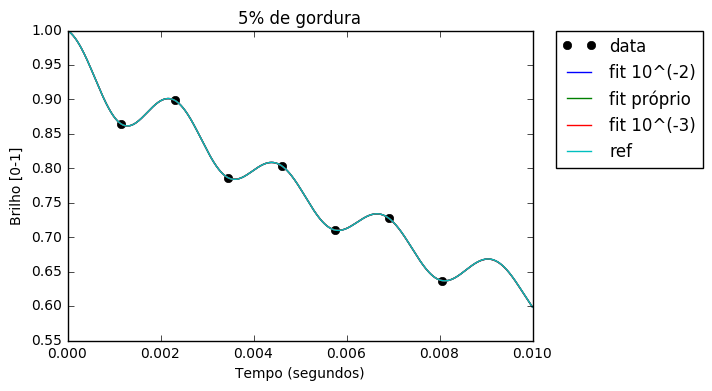

In [9]:
# "FITANDO OS DADOS"
popt1, pcov1 = curve_fit(fat_water, t,  Sfinal2, bounds=bd, p0=p1)
popt2, pcov2 = curve_fit(fat_water, t,  Sfinal2, bounds=bd, p0=p2) 
popt3, pcov3 = curve_fit(fat_water, t,  Sfinal2, bounds=bd, p0=p3) 

# PLOT DOS DADOS, FIT E REFERÊNCIA
plt.plot(t, Sfinal2,'ok', label='data')
plt.plot(x, fat_water(x,*popt1), label='fit 10^(-2)')
plt.plot(x, fat_water(x,*popt2), label='fit próprio')
plt.plot(x, fat_water(x,*popt3), label='fit 10^(-3)')
plt.plot(x, fat_water(x,*rho), label='ref')

# PLOT (BONITO)?
plt.title('5% de gordura')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Brilho [0-1]')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

## 10% de gordura

In [10]:
# GERANDO OS DADOS PARA 5% DE GORDURA

fatPercent = 0.1

t = [0.0011515, 0.0011515*2, 0.0011515*3, 0.0011515*4, 0.0011515*5, 0.0011515*6, 0.0011515*7]

rho = [fatPercent*0.047, fatPercent*0.039, fatPercent*0.006, fatPercent*0.12, fatPercent*0.7, fatPercent*0.088, 1-fatPercent]

Fppmn = np.array(Fppmn)

freq = [0,0,0,0,0,0,0]
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = np.array(freq)

counter = [0,1,2,3,4,5,6]
for n in counter:
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

rho = np.array(rho)
t = np.array(t)
T2star = np.array(T2star)


S = (7,7)
S = np.zeros(S,dtype='complex')
Sfinal= (7)
Sfinal=np.zeros(Sfinal,dtype='complex')


for n in counter:
    for index,TE in enumerate(t):
        S[n,index] = rho[n]*np.exp(-TE/T2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         

Sfinal = np.sum(S, axis=0)
Sfinal2 = np.absolute(Sfinal)

In [11]:
# BOUNDS
bd = (0, [1., 1., 1., 1., 1., 1., 1.])

# VALORES INICIAIS
p1 = rho + np.random.rand()*10**(-1) # PERTURBANDO A CASA 10^(-1)
p2 = rho                             # PRÓPRIO VALOR INICIAL
p3 = rho + np.random.rand()*10**(-2) # PERTURBANDO A CASA 10^(-2)

# PLOTAR A CURVA TODA
x = np.linspace(0,0.01,1001)

C:\Users\gaf_f\Anaconda3\lib\site-packages\scipy\optimize\minpack.py:715: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


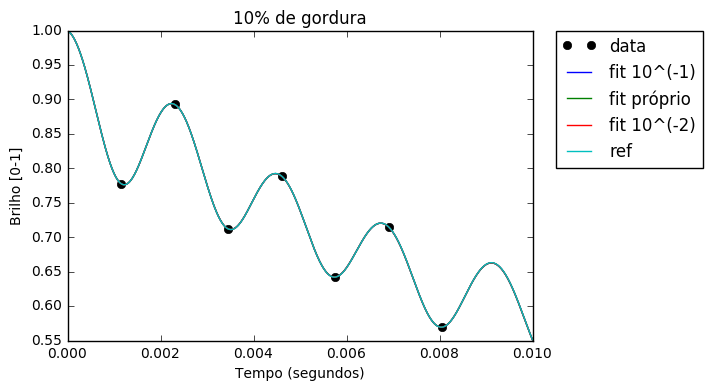

In [12]:
# "FITANDO OS DADOS"
popt1, pcov1 = curve_fit(fat_water, t,  Sfinal2, bounds=bd, p0=p1)
popt2, pcov2 = curve_fit(fat_water, t,  Sfinal2, bounds=bd, p0=p2) 
popt3, pcov3 = curve_fit(fat_water, t,  Sfinal2, bounds=bd, p0=p3) 

# PLOT DOS DADOS, FIT E REFERÊNCIA
plt.plot(t, Sfinal2,'ok', label='data')
plt.plot(x, fat_water(x,*popt1), label='fit 10^(-1)')
plt.plot(x, fat_water(x,*popt2), label='fit próprio')
plt.plot(x, fat_water(x,*popt3), label='fit 10^(-2)')
plt.plot(x, fat_water(x,*rho), label='ref')

# PLOT (BONITO)?
plt.title('10% de gordura')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Brilho [0-1]')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

## 20% de gordura

In [13]:
# GERANDO OS DADOS PARA 5% DE GORDURA

fatPercent = 0.2

t = [0.0011515, 0.0011515*2, 0.0011515*3, 0.0011515*4, 0.0011515*5, 0.0011515*6, 0.0011515*7]

rho = [fatPercent*0.047, fatPercent*0.039, fatPercent*0.006, fatPercent*0.12, fatPercent*0.7, fatPercent*0.088, 1-fatPercent]

Fppmn = np.array(Fppmn)

freq = [0,0,0,0,0,0,0]
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = np.array(freq)

counter = [0,1,2,3,4,5,6]
for n in counter:
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

rho = np.array(rho)
t = np.array(t)
T2star = np.array(T2star)


S = (7,7)
S = np.zeros(S,dtype='complex')
Sfinal= (7)
Sfinal=np.zeros(Sfinal,dtype='complex')


for n in counter:
    for index,TE in enumerate(t):
        S[n,index] = rho[n]*np.exp(-TE/T2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         

Sfinal = np.sum(S, axis=0)
Sfinal2 = np.absolute(Sfinal)

In [14]:
# BOUNDS
bd = (0, [1., 1., 1., 1., 1., 1., 1.])

# VALORES INICIAIS
p1 = rho + np.random.rand()*10**(-1) # PERTURBANDO A CASA 10^(-1)
p2 = rho                             # PRÓPRIO VALOR INICIAL
p3 = rho + np.random.rand()*10**(-2) # PERTURBANDO A CASA 10^(-2)

# PLOTAR A CURVA TODA
x = np.linspace(0,0.01,1001)

C:\Users\gaf_f\Anaconda3\lib\site-packages\scipy\optimize\minpack.py:715: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


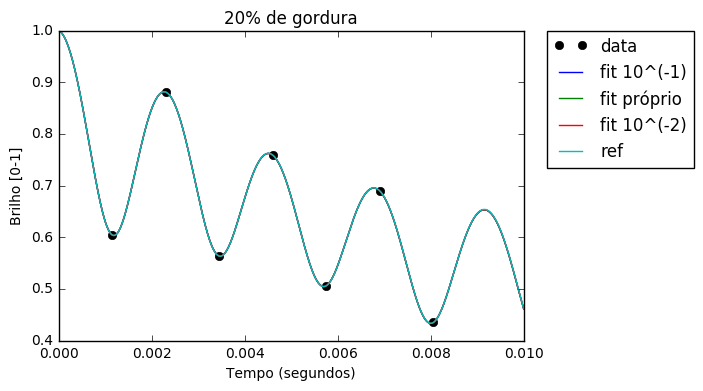

In [15]:
# "FITANDO OS DADOS"
popt1, pcov1 = curve_fit(fat_water, t,  Sfinal2, bounds=bd, p0=p1)
popt2, pcov2 = curve_fit(fat_water, t,  Sfinal2, bounds=bd, p0=p2) 
popt3, pcov3 = curve_fit(fat_water, t,  Sfinal2, bounds=bd, p0=p3) 

# PLOT DOS DADOS, FIT E REFERÊNCIA
plt.plot(t, Sfinal2,'ok', label='data')
plt.plot(x, fat_water(x,*popt1), label='fit 10^(-1)')
plt.plot(x, fat_water(x,*popt2), label='fit próprio')
plt.plot(x, fat_water(x,*popt3), label='fit 10^(-2)')
plt.plot(x, fat_water(x,*rho), label='ref')

# PLOT (BONITO)?
plt.title('20% de gordura')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Brilho [0-1]')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

## 30% de gordura

In [16]:
# GERANDO OS DADOS PARA 5% DE GORDURA

fatPercent = 0.3

t = [0.0011515, 0.0011515*2, 0.0011515*3, 0.0011515*4, 0.0011515*5, 0.0011515*6, 0.0011515*7]

rho = [fatPercent*0.047, fatPercent*0.039, fatPercent*0.006, fatPercent*0.12, fatPercent*0.7, fatPercent*0.088, 1-fatPercent]

Fppmn = np.array(Fppmn)

freq = [0,0,0,0,0,0,0]
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = np.array(freq)

counter = [0,1,2,3,4,5,6]
for n in counter:
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

rho = np.array(rho)
t = np.array(t)
T2star = np.array(T2star)


S = (7,7)
S = np.zeros(S,dtype='complex')
Sfinal= (7)
Sfinal=np.zeros(Sfinal,dtype='complex')


for n in counter:
    for index,TE in enumerate(t):
        S[n,index] = rho[n]*np.exp(-TE/T2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         

Sfinal = np.sum(S, axis=0)
Sfinal2 = np.absolute(Sfinal)

In [17]:
# BOUNDS
bd = (0, [1., 1., 1., 1., 1., 1., 1.])

# VALORES INICIAIS
p1 = rho + np.random.rand()*10**(-1) # PERTURBANDO A CASA 10^(-1)
p2 = rho                             # PRÓPRIO VALOR INICIAL
p3 = rho + np.random.rand()*10**(-2) # PERTURBANDO A CASA 10^(-2)

# PLOTAR A CURVA TODA
x = np.linspace(0,0.01,1001)

C:\Users\gaf_f\Anaconda3\lib\site-packages\scipy\optimize\minpack.py:715: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


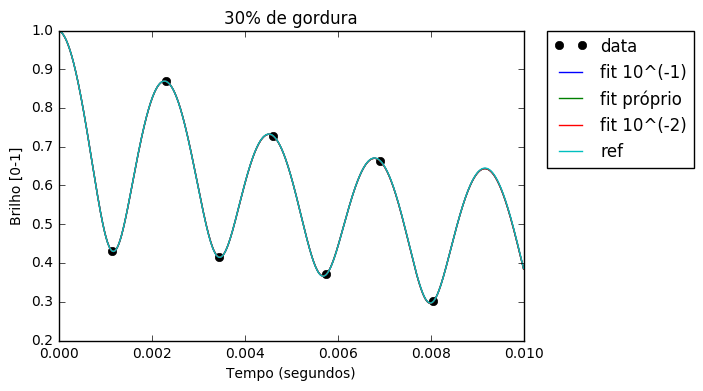

In [18]:
# "FITANDO OS DADOS"
popt1, pcov1 = curve_fit(fat_water, t,  Sfinal2, bounds=bd, p0=p1)
popt2, pcov2 = curve_fit(fat_water, t,  Sfinal2, bounds=bd, p0=p2) 
popt3, pcov3 = curve_fit(fat_water, t,  Sfinal2, bounds=bd, p0=p3) 

# PLOT DOS DADOS, FIT E REFERÊNCIA
plt.plot(t, Sfinal2,'ok', label='data')
plt.plot(x, fat_water(x,*popt1), label='fit 10^(-1)')
plt.plot(x, fat_water(x,*popt2), label='fit próprio')
plt.plot(x, fat_water(x,*popt3), label='fit 10^(-2)')
plt.plot(x, fat_water(x,*rho), label='ref')

# PLOT (BONITO)?
plt.title('30% de gordura')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Brilho [0-1]')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

## 40% de gordura

In [19]:
# GERANDO OS DADOS PARA 5% DE GORDURA

fatPercent = 0.4

t = [0.0011515, 0.0011515*2, 0.0011515*3, 0.0011515*4, 0.0011515*5, 0.0011515*6, 0.0011515*7]

rho = [fatPercent*0.047, fatPercent*0.039, fatPercent*0.006, fatPercent*0.12, fatPercent*0.7, fatPercent*0.088, 1-fatPercent]

Fppmn = np.array(Fppmn)

freq = [0,0,0,0,0,0,0]
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = np.array(freq)

counter = [0,1,2,3,4,5,6]
for n in counter:
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

rho = np.array(rho)
t = np.array(t)
T2star = np.array(T2star)


S = (7,7)
S = np.zeros(S,dtype='complex')
Sfinal= (7)
Sfinal=np.zeros(Sfinal,dtype='complex')


for n in counter:
    for index,TE in enumerate(t):
        S[n,index] = rho[n]*np.exp(-TE/T2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         

Sfinal = np.sum(S, axis=0)
Sfinal2 = np.absolute(Sfinal)

In [20]:
# BOUNDS
bd = (0, [1., 1., 1., 1., 1., 1., 1.])

# VALORES INICIAIS
p1 = rho + np.random.rand()*10**(-1) # PERTURBANDO A CASA 10^(-1)
p2 = rho                             # PRÓPRIO VALOR INICIAL
p3 = rho + np.random.rand()*10**(-2) # PERTURBANDO A CASA 10^(-2)

# PLOTAR A CURVA TODA
x = np.linspace(0,0.01,1001)

C:\Users\gaf_f\Anaconda3\lib\site-packages\scipy\optimize\minpack.py:715: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


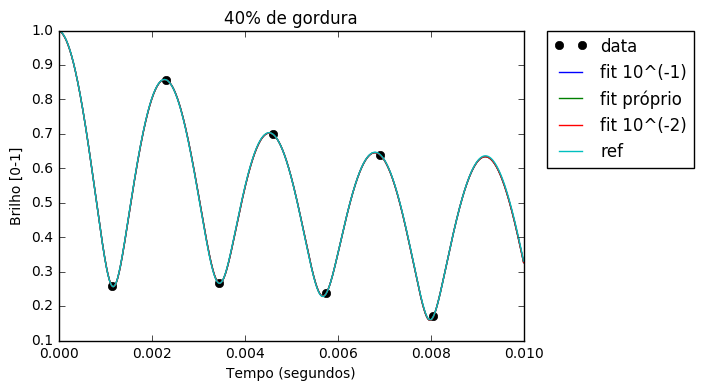

In [21]:
# "FITANDO OS DADOS"
popt1, pcov1 = curve_fit(fat_water, t,  Sfinal2, bounds=bd, p0=p1)
popt2, pcov2 = curve_fit(fat_water, t,  Sfinal2, bounds=bd, p0=p2) 
popt3, pcov3 = curve_fit(fat_water, t,  Sfinal2, bounds=bd, p0=p3) 

# PLOT DOS DADOS, FIT E REFERÊNCIA
plt.plot(t, Sfinal2,'ok', label='data')
plt.plot(x, fat_water(x,*popt1), label='fit 10^(-1)')
plt.plot(x, fat_water(x,*popt2), label='fit próprio')
plt.plot(x, fat_water(x,*popt3), label='fit 10^(-2)')
plt.plot(x, fat_water(x,*rho), label='ref')

# PLOT (BONITO)?
plt.title('40% de gordura')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Brilho [0-1]')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

## 50% de gordura

In [22]:
# GERANDO OS DADOS PARA 5% DE GORDURA

fatPercent = 0.5

t = [0.0011515, 0.0011515*2, 0.0011515*3, 0.0011515*4, 0.0011515*5, 0.0011515*6, 0.0011515*7]

rho = [fatPercent*0.047, fatPercent*0.039, fatPercent*0.006, fatPercent*0.12, fatPercent*0.7, fatPercent*0.088, 1-fatPercent]

Fppmn = np.array(Fppmn)

freq = [0,0,0,0,0,0,0]
magField = 3.0 #tesla
hydroGyro = 42.57e6 #Hz/T
freq = np.array(freq)

counter = [0,1,2,3,4,5,6]
for n in counter:
    freq[n] = Fppmn[n]*magField*hydroGyro/1e6

rho = np.array(rho)
t = np.array(t)
T2star = np.array(T2star)


S = (7,7)
S = np.zeros(S,dtype='complex')
Sfinal= (7)
Sfinal=np.zeros(Sfinal,dtype='complex')


for n in counter:
    for index,TE in enumerate(t):
        S[n,index] = rho[n]*np.exp(-TE/T2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         

Sfinal = np.sum(S, axis=0)
Sfinal2 = np.absolute(Sfinal)

In [23]:
# BOUNDS
bd = (0, [1., 1., 1., 1., 1., 1., 1.])

# VALORES INICIAIS
p1 = rho + np.random.rand()*10**(-1) # PERTURBANDO A CASA 10^(-1)
p2 = rho                             # PRÓPRIO VALOR INICIAL
p3 = rho + np.random.rand()*10**(-2) # PERTURBANDO A CASA 10^(-2)

# PLOTAR A CURVA TODA
x = np.linspace(0,0.01,1001)

C:\Users\gaf_f\Anaconda3\lib\site-packages\scipy\optimize\minpack.py:715: OptimizeWarning: Covariance of the parameters could not be estimated
  category=OptimizeWarning)


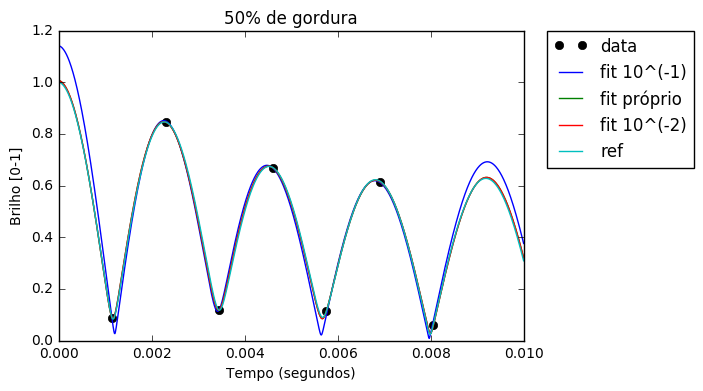

In [24]:
# "FITANDO OS DADOS"
popt1, pcov1 = curve_fit(fat_water, t,  Sfinal2, bounds=bd, p0=p1)
popt2, pcov2 = curve_fit(fat_water, t,  Sfinal2, bounds=bd, p0=p2) 
popt3, pcov3 = curve_fit(fat_water, t,  Sfinal2, bounds=bd, p0=p3) 

# PLOT DOS DADOS, FIT E REFERÊNCIA
plt.plot(t, Sfinal2,'ok', label='data')
plt.plot(x, fat_water(x,*popt1), label='fit 10^(-1)')
plt.plot(x, fat_water(x,*popt2), label='fit próprio')
plt.plot(x, fat_water(x,*popt3), label='fit 10^(-2)')
plt.plot(x, fat_water(x,*rho), label='ref')

# PLOT (BONITO)?
plt.title('50% de gordura')
plt.xlabel('Tempo (segundos)')
plt.ylabel('Brilho [0-1]')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

In [ ]:
import numpy as np
def discrete_GRE(fat_fraction, n_echoes, t2star):
    #this function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    #considering a low flip angle (Taylor approx. around zero) and 3T (TEs adjusted for 3T).
    #This is based on studies by Hamilton and Yokoo.
    #parameters: fat_fraction -> float ]0-1]
    #            n_echoes     -> integer >0, number of equally spaced echoes
    #            t2star       -> float ]0-np.inf], single t2* for everyone
    #returns:    Sabs (absolute signal intensity), echo_times
    
    #determine fat and water proton densities (rho) based on
    #a given fat fraction. rho_fat is arbitrarily defined as 0.05
    rho_fat = np.array(0.05)
    rho_water = np.array((rho_fat*((1-fat_fraction)/fat_fraction)))
    
    rho = np.array([rho_fat*0.047,\
      rho_fat*0.039,\
      rho_fat*0.006,\
      rho_fat*0.12,\
      rho_fat*0.7,\
      rho_fat*0.088,\
      rho_water]) #rho for each fat depends of the fat molecule (Hamilton)
    
    #TE acquisition times for n echoes
    echo_times = np.linspace(0.0011515, 0.0011515*n_echoes, n_echoes, endpoint=True)
    
    '''
    #standard, individual T2* values
    t2star = [0.030,\
              0.040,\
              0.051,\
              0.052,\
              0.062,\
              0.083,\
              0.023] '''
    
    #frequency in parts per million for each moiety
    freq_ppm = np.array([5.3,\
             4.2,\
             2.75,\
             2.1,\
             1.3,\
             0.9,\
             4.7])

    freq = np.zeros(len(freq_ppm))
    magField = np.array(3.0) #magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.57e6) #Hydrogen gyromagnetic ratio, Hz/T
    
    for n, fppm in enumerate(freq_ppm):
        freq[n] = fppm*magField*hydroGyro/1e6
    
    #calculate the complex signal for each moiety    
    S = (len(freq_ppm),len(echo_times))
    S = np.zeros(S,dtype='complex')
    
    for n, moieties in enumerate(freq_ppm):
        for t,TE in enumerate(echo_times):
            S[n,t] = rho[n]*np.exp(-TE/t2star)*np.exp(2.0*np.pi*1j*freq[n]*TE)         
    
    #obtain sum & absolute value
    Sabs= (len(echo_times))
    Sabs=np.zeros(Sabs,dtype='complex')
    
    Sabs = np.sum(S, axis=0)
    Sabs = np.absolute(Sabs)
    return (Sabs,echo_times)